# 02 — Démographie, cible de Citiz et villes à conquérir dans le Sud

---

## 🎯 Problématique

> ### Comment Citiz peut-il conquérir les grandes villes du Sud où il est absent, en ciblant ses vrais utilisateurs (actifs urbains sans voiture), sans reproduire l'échec des opérateurs qui ont déjà quitté Nice ?

**Pourquoi cette question** : le sujet demande où implanter de nouvelles stations pour toucher le plus d'habitants au moindre coût. Nos premières analyses montrent que Citiz est absent de grandes villes du Sud (Nice, Montpellier, Toulon…), que la concurrence en station y est faible ou a disparu, mais que la cible réelle de l'autopartage n'est pas celle qu'on imaginait (les jeunes). La problématique relie ces trois constats.

**Réponse courte** (détaillée en partie 11) :
- **Cible** : des actifs urbains sans voiture, surtout de 40-50 ans (ADEME 2022), pas les étudiants. Nous retenons les **25-54 ans sans voiture**.
- **Villes** : **Nice en priorité 1**, **Montpellier en priorité 2**, quel que soit l'âge adulte retenu.
- **Marché atteignable** : environ **80 à 175 véhicules à Nice** et **64 à 139 à Montpellier**, avec la couverture que Citiz a déjà ailleurs.
- **Condition** : un pilote mesuré et des contrats entreprises, pour ne pas répéter les arrêts d'opérateurs à Nice.

---

Questions traitées, dans l'ordre :

1. **Les données sont-elles fiables ?** Nettoyage et état des lieux de l'offre (parties 1 et 2).
2. **Où vivent les habitants, les jeunes et les ménages sans voiture** dans les 11 grandes villes du Sud et leur périphérie (parties 3 à 6) ?
3. **Qui est la cible de Citiz ?** Les sources externes, puis un test sur nos données (parties 7 et 8).
4. **Quelles villes viser, pour quel marché ?** (parties 9 et 10).

**Données (officielles ou publiques)**

| Donnée | Source | Millésime |
|---|---|---|
| Population par âge (année par année), commune / métropole / aire d'attraction, et pour les 34 852 communes | INSEE, recensement, [tableaux détaillés](https://www.insee.fr/fr/statistiques/9006235) | 2023 |
| Ménages selon le nombre de voitures, logement, statut d'occupation | INSEE, [base logement communale](https://www.insee.fr/fr/statistiques/8581474) | 2022 |
| Contours et rattachement des communes | API Géo (etalab / IGN) | 2026 |
| Stations Citiz, concurrents, Getaround (nettoyés) | GBFS, [transport.data.gouv.fr](https://transport.data.gouv.fr) | oct. 2026 |
| Profil des usagers de l'autopartage | Enquête nationale ADEME / 6t | 2022 |

**À noter** : « habitants à l'année » = **population municipale légale** (résidents permanents). La population saisonnière (tourisme) n'est pas dans ces données.

Fichiers nettoyés : `data/clean/` (scripts `scripts/clean_data.py` et `scripts/prepare_communes.py`).

In [1]:
import json, re, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import shape, Point
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
GREEN, ORANGE, GREY, BLUE, PURPLE = "#00843D", "#E07B00", "#9AA0A6", "#4C78A8", "#7B2CBF"

RAW, CLEAN = Path("../data/raw"), Path("../data/clean")
BORNE_INF, BORNE_SUP = 18, 26   # définition « jeunes » retenue pour l'étude

## 1. Nettoyage : ce qui a été corrigé

In [2]:
display(Markdown((CLEAN / "data_quality_report.md").read_text(encoding="utf-8")))

# Rapport de qualité des données

*Généré le 20/10/2026 08:56.*

## 1. Stations Citiz

Fichier : `citiz_stations_2026-10-20.csv` — **1615 lignes** brutes, 15 réseaux régionaux.

- coordonnées manquantes ou hors France : **0**
- doublons de lieu (mêmes coordonnées à 10 m près, p. ex. Lyon présent dans deux flux) : **11** supprimés
- stations « Flex » (zone d'usage à part, non assimilables à une station classique) : **23** conservées, marquées `flex`
- stations sans véhicule rattaché : **96** conservées, marquées `sans_vehicule` (à exclure du comptage de flotte, utiles pour l'emprise)
- géocodage inverse : 1604 nouveaux points (API Géo)
- rattachement à une commune : 1604/1604 (échecs : 0)

**Résultat : 1604 stations, 2624 véhicules** → `data/clean/citiz_stations.csv` (11 lignes écartées au total).

## 2. Concurrents (Clem', Optymo, Leo&Go)

Fichier : `competitors_2026-10-20.csv` — **794 lignes** brutes.

- coordonnées aberrantes : **0**
- Clem' publie une station par place : 459 stations pour 325 sites distincts → **regroupées par site** (un site = plusieurs véhicules)
- Optymo : 31 stations sans véhicule disponible au moment du relevé (conservées, `n_vehicles = 0`)
- Leo&Go : véhicules en free-floating, **photo à un instant T** (pas une implantation fixe)
- géocodage inverse : 602 nouveaux points (API Géo)

**Résultat : 654 sites, 763 véhicules** → `data/clean/competitor_sites.csv`.

## 3. Getaround

Cache : `getaround_2026-10-19` — **1803/3753 flux** (48%), 110,678 lignes brutes.

- doublons entre flux voisins (un véhicule apparaît dans plusieurs villes) : **101,499** supprimés
- coordonnées aberrantes : **0**
- hors territoire (mer, pays frontaliers) : **0** écartés

**Résultat : 9,179 véhicules uniques** → `data/clean/getaround_vehicles.csv`. ⚠️ **Collecte partielle (48% des flux)** : les volumes Getaround sont des planchers.

## 4. Limites qui ne se corrigent pas par le nettoyage

- **Photo à un instant T** : aucune mesure d'usage (locations, taux d'occupation) dans les flux ouverts.
- **Opérateurs sans flux GBFS** (Modulauto, Zity, Free2Move, Ubeeqo, Marcel, Mobilize Share) : absents.
- **Getaround** : voitures de particuliers, pas comparables une à une à des véhicules Citiz.
- **Fichiers datés en double** (19 et 20 octobre) : seul le plus récent est utilisé ; les anciens sont conservés dans `data/raw/`.


In [3]:
# Avant / après nettoyage
avant = {"Citiz (stations)": len(pd.read_csv(sorted(RAW.glob("citiz_stations_*.csv"))[-1])),
         "Concurrents (points)": len(pd.read_csv(sorted(RAW.glob("competitors_*.csv"))[-1])),
         "Getaround (lignes de flux)": 110678}
citiz = pd.read_csv(CLEAN / "citiz_stations.csv", dtype={"id": str, "commune_code": str, "dep": str})
comp = pd.read_csv(CLEAN / "competitor_sites.csv", dtype={"commune_code": str, "dep": str})
ga = pd.read_csv(CLEAN / "getaround_vehicles.csv", dtype={"id": str, "dep": str})
apres = {"Citiz (stations)": len(citiz), "Concurrents (points)": len(comp), "Getaround (lignes de flux)": len(ga)}
q = pd.DataFrame({"avant": avant, "après": apres}); q["écartés / regroupés"] = q.avant - q["après"]
q["% conservé"] = 100 * q["après"] / q.avant
q

,avant,après,écartés / regroupés,% conservé
Citiz (stations),1615,1604,11,99.3
Concurrents (points),794,654,140,82.4
Getaround (lignes de flux),110678,9179,101499,8.3


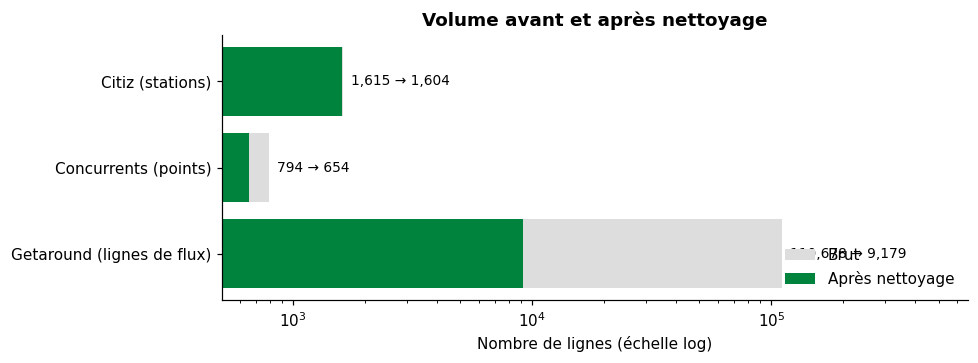

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.4))
q2 = q.iloc[::-1]
ax.barh(q2.index, q2["avant"], color="#DDDDDD", label="Brut")
ax.barh(q2.index, q2["après"], color=GREEN, label="Après nettoyage")
ax.set_xscale("log"); ax.set_xlabel("Nombre de lignes (échelle log)")
for y, (a, b) in enumerate(zip(q2.avant, q2["après"])): ax.text(a * 1.08, y, f"{a:,} → {b:,}", va="center", fontsize=9)
ax.set_xlim(right=q2.avant.max() * 6); ax.legend(frameon=False, loc="lower right")
ax.set_title("Volume avant et après nettoyage"); plt.tight_layout(); plt.show()

**Ce que le nettoyage change vraiment** : (1) 11 doublons Citiz (Lyon était dans deux flux) ; (2) Clem' publie une ligne par place : 459 lignes deviennent 325 sites ; (3) **101 499 doublons Getaround**, parce qu'un véhicule apparaît dans plusieurs villes voisines (sans ce traitement, Getaround serait compté douze fois trop) ; (4) chaque point est rattaché à **sa commune et son département** (API Géo), ce qui permet de croiser avec l'INSEE ; (5) 96 stations Citiz sans véhicule et 23 stations « Flex » sont **marquées** et non supprimées, pour que l'analyse décide si elles comptent.

## 2. État des lieux avec les données nettoyées

Citiz : 1604 stations, 2624 véhicules, 294 communes, 47 départements.


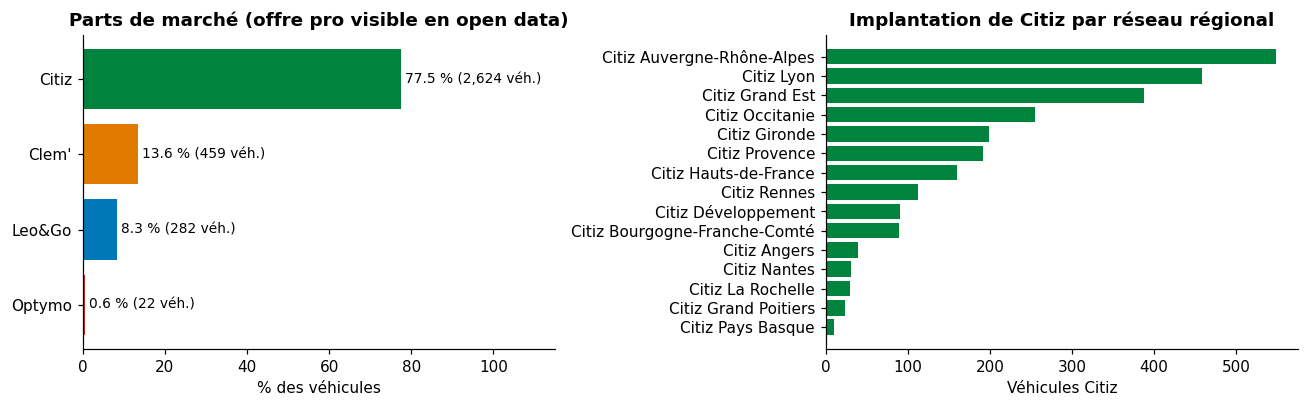

In [5]:
veh = citiz[~citiz.sans_vehicule]
print(f"Citiz : {len(citiz)} stations, {int(citiz.n_vehicles.sum())} véhicules, {citiz.commune_code.nunique()} communes, "
      f"{citiz.dep.nunique()} départements.")
part = pd.Series({"Citiz": citiz.n_vehicles.sum(), **comp.groupby("operator").n_vehicles.sum().to_dict()})
part_pro = 100 * part / part.sum()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colors = {"Citiz": GREEN, "Clem'": ORANGE, "Leo&Go": "#0077B6", "Optymo": "#D62828"}
p = part_pro.sort_values()
axes[0].barh(p.index, p.values, color=[colors[i] for i in p.index])
for y, (i, v) in enumerate(p.items()): axes[0].text(v + 1, y, f"{v:.1f} % ({int(part[i]):,} véh.)", va="center", fontsize=9)
axes[0].set_xlim(0, 115); axes[0].set_xlabel("% des véhicules"); axes[0].set_title("Parts de marché (offre pro visible en open data)")
top = citiz.groupby("network").agg(stations=("id", "size"), vehicules=("n_vehicles", "sum")).sort_values("vehicules")
axes[1].barh(top.index, top.vehicules, color=GREEN)
axes[1].set_xlabel("Véhicules Citiz"); axes[1].set_title("Implantation de Citiz par réseau régional")
plt.tight_layout(); plt.show()

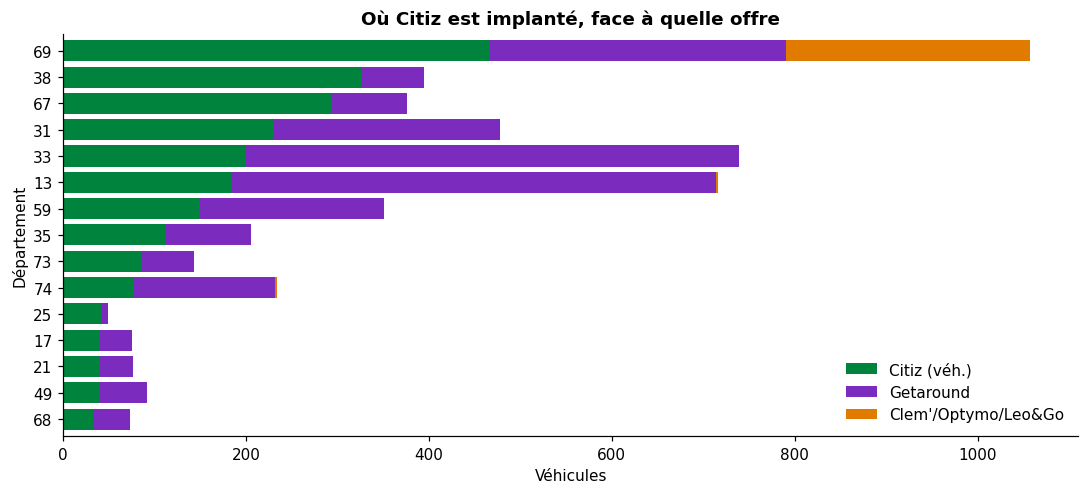

In [6]:
# Les 15 départements où Citiz est le plus implanté, et part de Getaround dans ces départements
dep = pd.DataFrame({"Citiz (véh.)": citiz.groupby("dep").n_vehicles.sum(), "Getaround": ga.groupby("dep").size(),
                    "Clem'/Optymo/Leo&Go": comp.groupby("dep").n_vehicles.sum()}).fillna(0)
dep = dep.sort_values("Citiz (véh.)", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 4.6))
dep.iloc[::-1].plot.barh(stacked=True, ax=ax, color=[GREEN, PURPLE, ORANGE], width=.8)
ax.set_xlabel("Véhicules"); ax.set_ylabel("Département"); ax.set_title("Où Citiz est implanté, face à quelle offre")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3. Chargement des données démographiques

In [7]:
# --- Population par âge (INSEE RP 2023) ---
pop = pd.read_csv(RAW / "insee/pop_age_sud_2023.csv", dtype={"geo_code": str})
pop["age_n"] = pop["age"].map(lambda a: 100 if a == "Y_GE100" else (int(a[1:]) if a.startswith("Y") else np.nan))

def effectif(ville, niveau, lo=None, hi=None):
    d = pop[(pop.ville == ville) & (pop.niveau == niveau)]
    if lo is None:
        return d.loc[d.age == "_T", "population"].sum()
    return d.loc[d.age_n.between(lo, hi), "population"].sum()

# --- Ménages sans voiture (INSEE logement 2022) : lecture limitée aux 11 communes ---
CODES = {"Marseille": "13055", "Nice": "06088", "Montpellier": "34172", "Toulouse": "31555", "Bordeaux": "33063",
         "Toulon": "83137", "Nîmes": "30189", "Perpignan": "66136", "Aix-en-Provence": "13001",
         "Avignon": "84007", "Béziers": "34032"}
log = pd.read_csv(RAW / "insee/menages_voitures_sud_2022.csv", dtype={"CODGEO": str}).set_index("CODGEO")

# --- Contours officiels des communes ---
contours = {v: shape(j["contour"]) for v, j in json.loads((RAW / "insee/communes_contours.json").read_text()).items()}

# --- Offre d'autopartage : fichiers nettoyés chargés en partie 1 (citiz, comp, ga) ---

def compter(df, poly, col=None):
    d = df[[poly.contains(Point(lo, la)) for la, lo in zip(df.lat, df.lon)]] if len(df) else df
    return (d[col].sum() if col else len(d))

## 4. Population à l'année : commune, métropole, aire d'attraction

Trois échelles INSEE : la **commune** (ville centre), la **métropole / agglomération** (EPCI) et l'**aire d'attraction** (périphérie élargie, qui regroupe les communes dont les habitants travaillent dans la ville). Aix-en-Provence est dans la métropole d'Aix-Marseille-Provence et dans l'aire de Marseille.

In [8]:
villes = list(CODES)
rows = []
for v in villes:
    r = {"ville": v, "pop_commune": effectif(v, "commune"), "pop_metropole": effectif(v, "metropole") or np.nan,
         "pop_aire": effectif(v, "aire_attraction")}
    for nom, lo, hi in [("j1826", 18, 26), ("a2744", 27, 44), ("a2544", 25, 44)]:
        for niv, key in [("commune", "com"), ("metropole", "met"), ("aire_attraction", "aire")]:
            r[f"{nom}_{key}"] = effectif(v, niv, lo, hi) or np.nan
    c = log.loc[CODES[v]]
    r["sans_voiture"] = 1 - c["P22_RP_VOIT1P"] / c["P22_RP"]
    r["menages"] = c["P22_RP"]
    p = contours[v]
    r["citiz_stations"] = compter(citiz, p)
    r["citiz_veh"] = compter(citiz, p, "n_vehicles")
    r["getaround"] = compter(ga, p)
    for op in ["Clem'", "Optymo", "Leo&Go"]:
        r[op] = compter(comp[comp.operator == op], p, "n_vehicles")
    rows.append(r)
d = pd.DataFrame(rows).set_index("ville").sort_values("pop_commune", ascending=False)
d["part_j1826"] = d.j1826_com / d.pop_commune
d["part_a2544"] = d.a2544_com / d.pop_commune
d["citiz_present"] = d.citiz_veh >= 20   # moins de 20 véhicules (Avignon : 6) = présence marginale, traitée comme absent
d["offre_pro"] = d.citiz_veh + d["Clem'"] + d["Optymo"] + d["Leo&Go"]
d.to_csv(Path("../outputs") / "demographie_cible_sud.csv")

disp = d[["pop_commune", "pop_metropole", "pop_aire", "j1826_com", "part_j1826", "a2544_com", "sans_voiture",
          "citiz_veh", "getaround", "offre_pro"]].copy()
disp["part_j1826"] *= 100; disp["sans_voiture"] *= 100
disp.columns = ["Pop. commune", "Pop. métropole", "Pop. aire", "18-26 ans (commune)", "% 18-26", "25-44 ans (commune)",
                "% ménages sans voiture", "Véh. Citiz", "Getaround", "Offre pro (hors Getaround)"]
disp

,Pop. commune,Pop. métropole,Pop. aire,18-26 ans (commune),% 18-26,25-44 ans (commune),% ménages sans voiture,Véh. Citiz,Getaround,Offre pro (hors Getaround)
ville,,,,,,,,,,
Marseille,"886,040.0","1,939,077.0","1,917,728.0","107,115.0",12.1,"232,378.3",33.2,185.0,334,185.0
Toulouse,"514,819.0","841,524.0","1,529,112.0","121,319.6",23.6,"168,027.3",32.8,176.0,178,176.0
Nice,"357,737.0","574,287.0","641,721.0","42,398.8",11.9,"87,104.5",37.4,0.0,150,0.0
Montpellier,"310,240.0","522,542.0","842,923.0","72,783.8",23.5,"90,952.0",31.7,0.0,124,0.0
Bordeaux,"267,991.0","854,334.0","1,426,278.0","56,660.7",21.1,"84,805.2",37.2,153.0,393,153.0
Toulon,"179,116.0","450,549.0","591,135.0","19,537.9",10.9,"44,749.6",26.3,0.0,101,0.0
Nîmes,"151,839.0","264,025.0","357,349.0","21,441.0",14.1,"35,192.0",25.4,0.0,30,0.0
Aix-en-Provence,"149,695.0",NaN,"1,917,728.0","29,095.8",19.4,"38,770.9",23.7,0.0,121,0.0
Perpignan,"121,616.0","279,615.0","432,128.0","14,864.0",12.2,"28,279.1",26.0,0.0,40,0.0


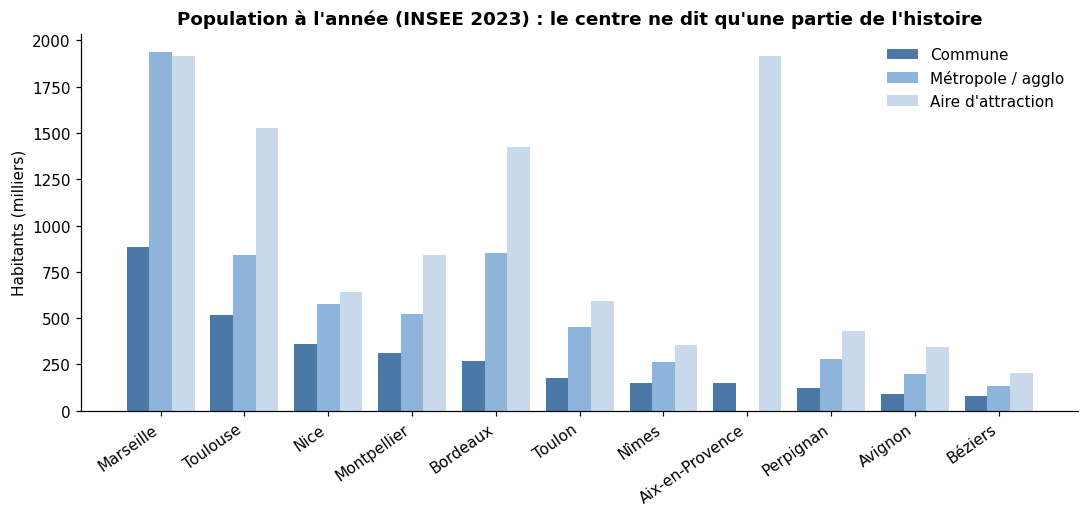

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(d)); w = 0.27
ax.bar(x - w, d.pop_commune / 1e3, w, label="Commune", color=BLUE)
ax.bar(x, d.pop_metropole / 1e3, w, label="Métropole / agglo", color="#8FB4DC")
ax.bar(x + w, d.pop_aire / 1e3, w, label="Aire d'attraction", color="#C9D9EC")
ax.set_xticks(x, d.index, rotation=35, ha="right"); ax.set_ylabel("Habitants (milliers)")
ax.set_title("Population à l'année (INSEE 2023) : le centre ne dit qu'une partie de l'histoire")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 5. Les jeunes de 18 à 26 ans

### 5.1 Effectifs et part dans la population (commune)

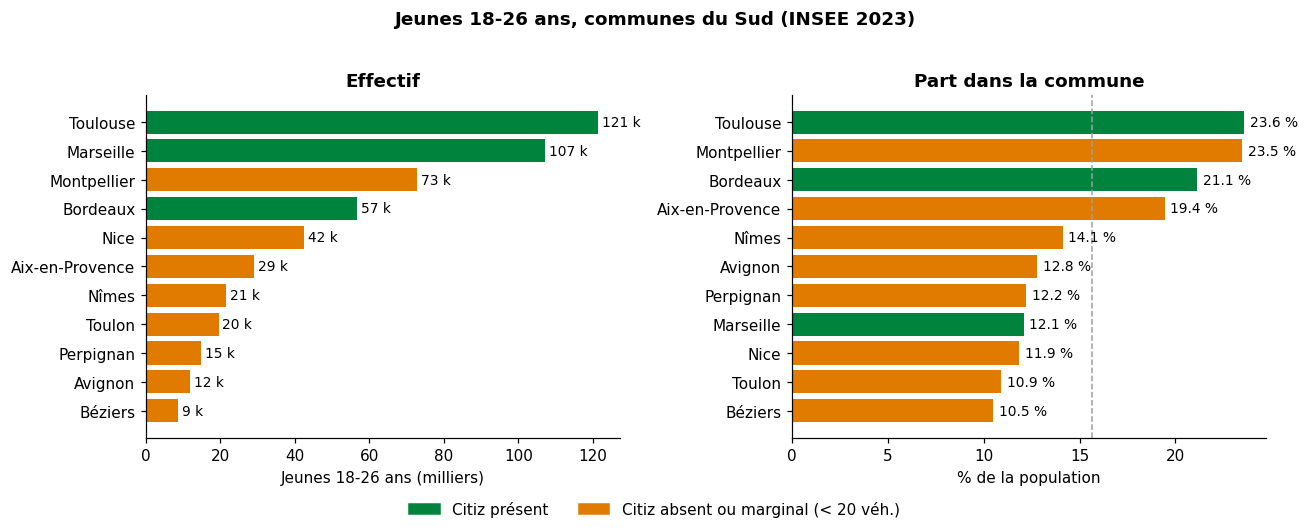

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
o = d.sort_values("j1826_com")
axes[0].barh(o.index, o.j1826_com / 1e3, color=[GREEN if p else ORANGE for p in o.citiz_present])
for y, v in enumerate(o.j1826_com / 1e3): axes[0].text(v + 1, y, f"{v:,.0f} k", va="center", fontsize=9)
axes[0].set_xlabel("Jeunes 18-26 ans (milliers)"); axes[0].set_title("Effectif")
o = d.sort_values("part_j1826")
axes[1].barh(o.index, o.part_j1826 * 100, color=[GREEN if p else ORANGE for p in o.citiz_present])
for y, v in enumerate(o.part_j1826 * 100): axes[1].text(v + .3, y, f"{v:.1f} %", va="center", fontsize=9)
axes[1].axvline(d.part_j1826.mean() * 100, color=GREY, ls="--", lw=1)
axes[1].set_xlabel("% de la population"); axes[1].set_title("Part dans la commune")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=GREEN, label="Citiz présent"), Patch(color=ORANGE, label="Citiz absent ou marginal (< 20 véh.)")],
           loc="lower center", ncol=2, frameon=False)
plt.suptitle("Jeunes 18-26 ans, communes du Sud (INSEE 2023)", fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 0.96)); plt.show()

### 5.2 Profil d'âge : quelles villes sont réellement « jeunes » ?

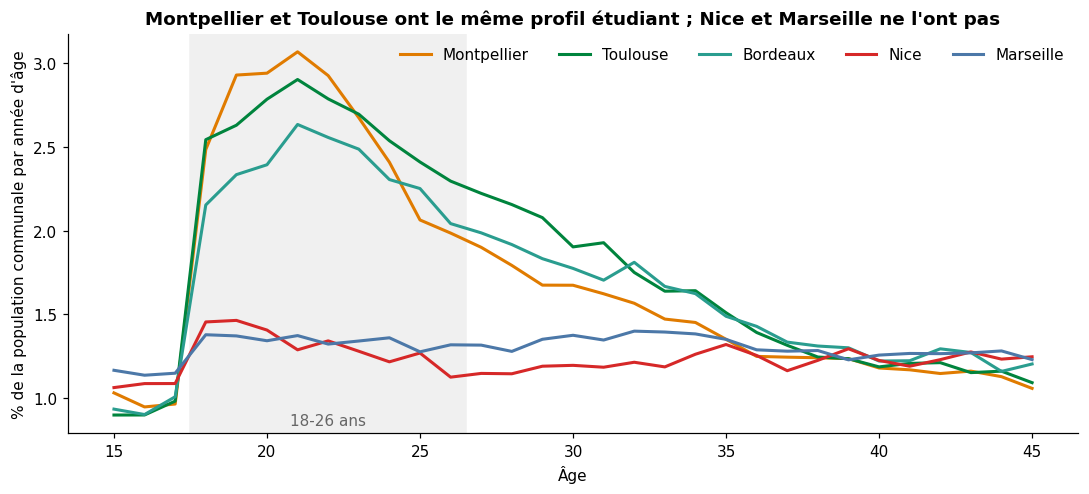

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.6))
sel = {"Montpellier": ORANGE, "Toulouse": GREEN, "Bordeaux": "#2A9D8F", "Nice": "#D62828", "Marseille": BLUE}
for v, col in sel.items():
    s = pop[(pop.ville == v) & (pop.niveau == "commune") & pop.age_n.between(15, 45)].set_index("age_n").population
    ax.plot(s.index, 100 * s / effectif(v, "commune"), label=v, color=col, lw=2)
ax.axvspan(BORNE_INF - .5, BORNE_SUP + .5, color="#F0F0F0", zorder=0)
ax.text(22, ax.get_ylim()[0] + .03, "18-26 ans", ha="center", va="bottom", color="#666")
ax.set_xlabel("Âge"); ax.set_ylabel("% de la population communale par année d'âge")
ax.set_title("Montpellier et Toulouse ont le même profil étudiant ; Nice et Marseille ne l'ont pas")
ax.legend(frameon=False, ncol=5); plt.tight_layout(); plt.show()

### 5.3 Où vivent-ils : centre ou périphérie ?

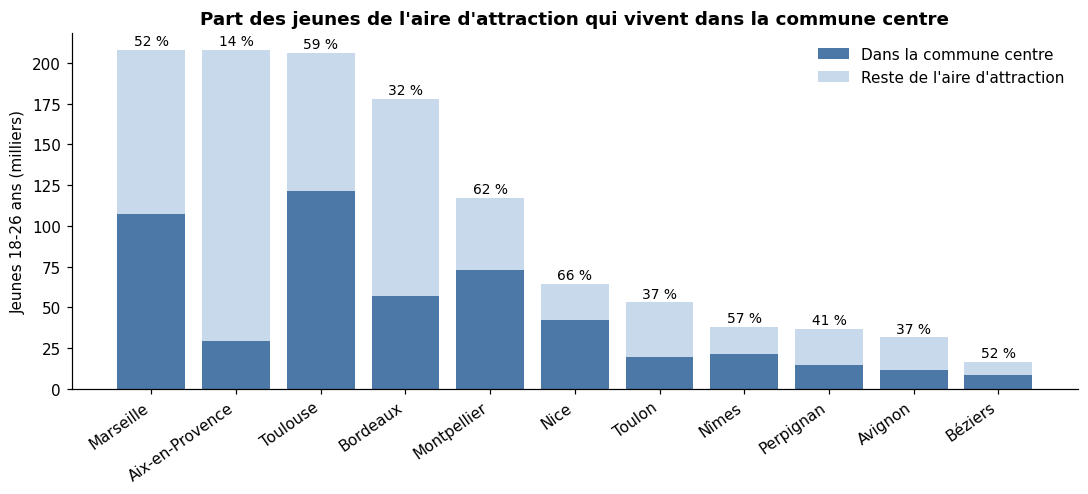

In [12]:
c = d.copy()
c["reste_aire"] = c.j1826_aire - c.j1826_com
fig, ax = plt.subplots(figsize=(10, 4.6))
o = c.sort_values("j1826_aire", ascending=False)
ax.bar(o.index, o.j1826_com / 1e3, color=BLUE, label="Dans la commune centre")
ax.bar(o.index, o.reste_aire / 1e3, bottom=o.j1826_com / 1e3, color="#C9D9EC", label="Reste de l'aire d'attraction")
for i, (v, r) in enumerate(o.iterrows()):
    ax.text(i, (r.j1826_aire) / 1e3 + 3, f"{100 * r.j1826_com / r.j1826_aire:.0f} %", ha="center", fontsize=9)
ax.set_ylabel("Jeunes 18-26 ans (milliers)"); plt.xticks(rotation=35, ha="right")
ax.set_title("Part des jeunes de l'aire d'attraction qui vivent dans la commune centre")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Motorisation : une cible sans voiture ?

Les abonnés à l'autopartage en boucle vivent à **73,8 % dans un ménage sans voiture** (enquête nationale ADEME/6t 2022, 1 813 répondants). La part de ménages sans voiture est donc le meilleur proxy disponible en open data.

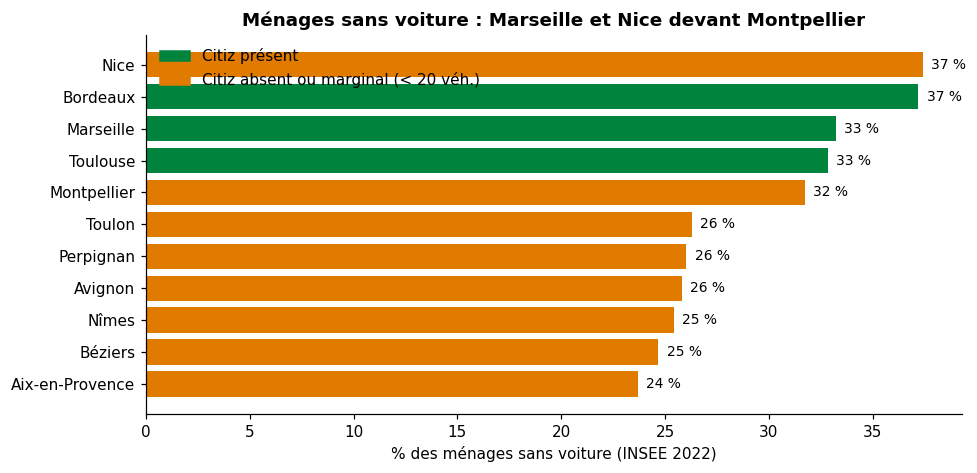

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.4))
o = d.sort_values("sans_voiture")
ax.barh(o.index, o.sans_voiture * 100, color=[GREEN if p else ORANGE for p in o.citiz_present])
for y, v in enumerate(o.sans_voiture * 100): ax.text(v + .4, y, f"{v:.0f} %", va="center", fontsize=9)
ax.set_xlabel("% des ménages sans voiture (INSEE 2022)")
ax.set_title("Ménages sans voiture : Marseille et Nice devant Montpellier")
ax.legend(handles=[Patch(color=GREEN, label="Citiz présent"), Patch(color=ORANGE, label="Citiz absent ou marginal (< 20 véh.)")], frameon=False)
plt.tight_layout(); plt.show()

### 6.1 L'offre d'autopartage actuelle rapportée aux jeunes

⚠️ Ne sont comptés ici que les opérateurs **avec flux GBFS ouvert** (Citiz, Clem', Optymo, Leo&Go, Getaround). **Modulauto (Montpellier) et Mobilize Share (Nice, arrêté en juin 2026) sont absents** : à Montpellier, l'offre réelle est sous-estimée.

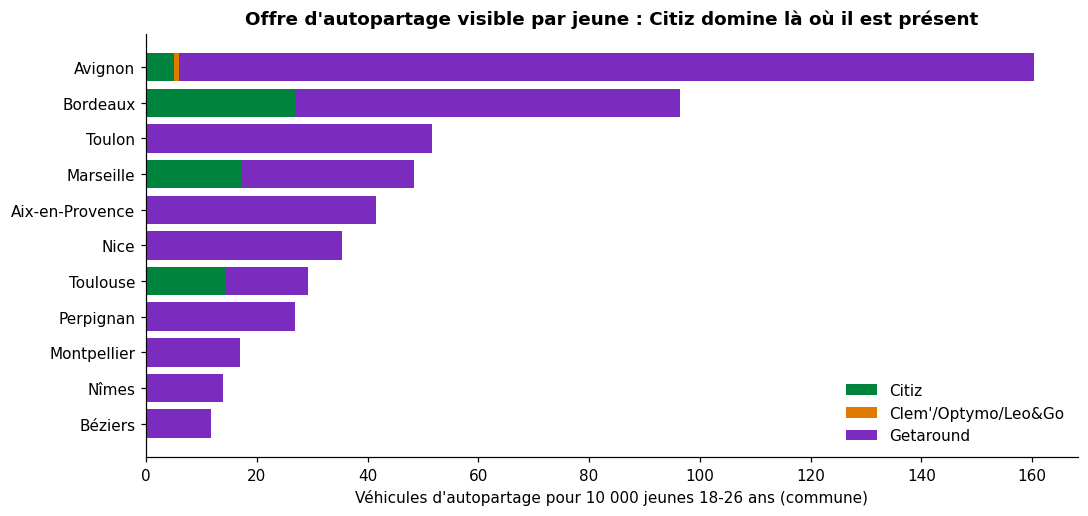

,Citiz,Clem'/Optymo/Leo&Go,Getaround
ville,,,
Béziers,0.0,0.0,11.7
Nîmes,0.0,0.0,14.0
Montpellier,0.0,0.0,17.0
Perpignan,0.0,0.0,26.9
Toulouse,14.5,0.0,14.7
Nice,0.0,0.0,35.4
Aix-en-Provence,0.0,0.0,41.6
Marseille,17.3,0.0,31.2
Toulon,0.0,0.0,51.7


In [14]:
fig, ax = plt.subplots(figsize=(10, 4.8))
t = pd.DataFrame({"Citiz": d.citiz_veh, "Clem'/Optymo/Leo&Go": d["Clem'"] + d.Optymo + d["Leo&Go"], "Getaround": d.getaround})
t = t.div(d.j1826_com, axis=0) * 10000
t = t.loc[t.sum(axis=1).sort_values().index]
left = np.zeros(len(t))
for col, color in [("Citiz", GREEN), ("Clem'/Optymo/Leo&Go", ORANGE), ("Getaround", "#7B2CBF")]:
    ax.barh(t.index, t[col], left=left, color=color, label=col); left += t[col].values
ax.set_xlabel("Véhicules d'autopartage pour 10 000 jeunes 18-26 ans (commune)")
ax.set_title("Offre d'autopartage visible par jeune : Citiz domine là où il est présent")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()
t.round(1)

### 6.2 Croisement : potentiel de la cible contre offre pro existante

Axe horizontal : part des 18-26 ans. Axe vertical : part de ménages sans voiture. Taille : nombre de jeunes. Couleur : Citiz présent ou non. **Le coin haut-droite sans Citiz est la zone d'intérêt.**

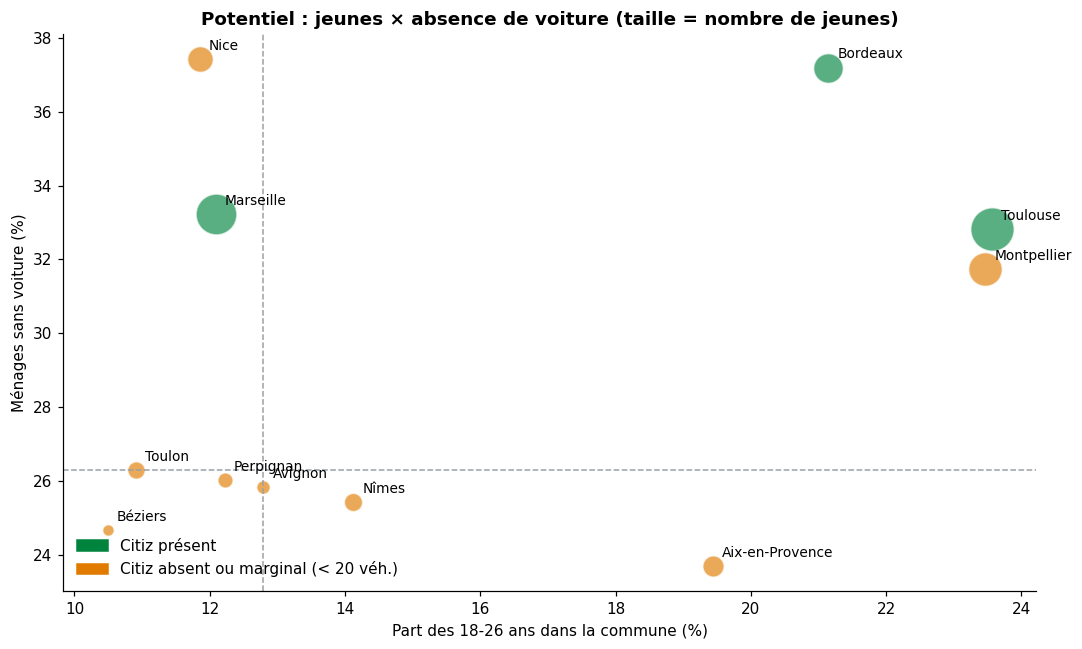

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
for v, r in d.iterrows():
    ax.scatter(r.part_j1826 * 100, r.sans_voiture * 100, s=r.j1826_com / 150, color=GREEN if r.citiz_present else ORANGE,
               alpha=.65, edgecolor="white", lw=1)
    ax.annotate(v, (r.part_j1826 * 100, r.sans_voiture * 100), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.axvline(d.part_j1826.median() * 100, color=GREY, ls="--", lw=1); ax.axhline(d.sans_voiture.median() * 100, color=GREY, ls="--", lw=1)
ax.set_xlabel("Part des 18-26 ans dans la commune (%)"); ax.set_ylabel("Ménages sans voiture (%)")
ax.set_title("Potentiel : jeunes × absence de voiture (taille = nombre de jeunes)")
ax.legend(handles=[Patch(color=GREEN, label="Citiz présent"), Patch(color=ORANGE, label="Citiz absent ou marginal (< 20 véh.)")], frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

## 7. Qui est la cible de Citiz ? Ce que disent les sources

| Constat | Valeur | Source |
|---|---|---|
| Âge des usagers de l'**autopartage en boucle** (modèle de Citiz) | « **entre 40 et 50 ans** » | Enquête ADEME/6t 2022 (1 813 usagers en boucle) |
| Âge des usagers du free-floating | 30 à 40 ans | même enquête |
| Âge moyen des usagers Getaround Connect | environ 40 ans | même enquête |
| En activité | 80 % (contre 56 % en France) | même enquête |
| Bac +5 ou plus | 58 % (contre 10,5 % en France) | même enquête |
| Sans véhicule | 74 % (contre 30 % des ménages) | même enquête |
| Âge moyen, usagers d'un service local (Montpellier, 2018, non représentatif) | 44 ans | mémoire d'étude |
| Âge médian, usagers particuliers d'un service du Mans | 48 ans | communication de recherche (CIRRELT 2019) |
| Inscrits depuis moins de 2 ans | 50 % (enquête 2019, 3 777 répondants) | 6t 2019 |
| Cibles à développer | jeunes retraités, jeunes, ménages moins aisés | 6t 2019/ADEME 2022 |

**Premier enseignement : l'hypothèse 25-44 ans est trop basse.** Pour l'autopartage en boucle, les sources convergent vers **40-50 ans**, actifs, très diplômés, sans voiture. **25-44 ans est la tranche standard la plus proche, mais elle couvre une partie des utilisateurs du free-floating (30-40 ans) plus que ceux de Citiz.** Nous testons donc aussi 35-54 et 40-50 ans.

## 8. Test sur nos données : où Citiz est-il implanté ?

**Méthode** : on prend les **482 communes de plus de 20 000 habitants** (INSEE 2023) et on regarde si les communes où Citiz a des stations ont une structure d'âge particulière. ⚠️ Ceci mesure **où Citiz a implanté ses stations** (offre), pas **qui les utilise** (demande). C'est un indice, pas une preuve.

In [16]:
com = pd.read_csv(CLEAN / "communes_demo.csv", dtype={"code": str})
veh_com = citiz[~citiz.sans_vehicule].groupby("commune_code").n_vehicles.sum().rename("veh")
dn = com.merge(veh_com, left_on="code", right_index=True, how="left").fillna({"veh": 0})
big = dn[dn["pop"] >= 20000].copy()
big["present"] = big.veh > 0
big["veh10k"] = big.veh / big["pop"] * 1e4
BANDES = {"18-26": "p18_26", "27-34": "p27_34", "35-44": "p35_44", "45-54": "p45_54", "55-64": "p55_64", "65+": "p65_plus"}
for lab, col in {**BANDES, "25-44": "p25_44", "35-54": "p35_54", "40-50": "p40_50"}.items():
    big["s_" + lab] = big[col] / big["pop"]
print(f"{len(big)} communes de plus de 20 000 habitants, dont {int(big.present.sum())} avec Citiz (au moins un véhicule).")

482 communes de plus de 20 000 habitants, dont 101 avec Citiz (au moins un véhicule).


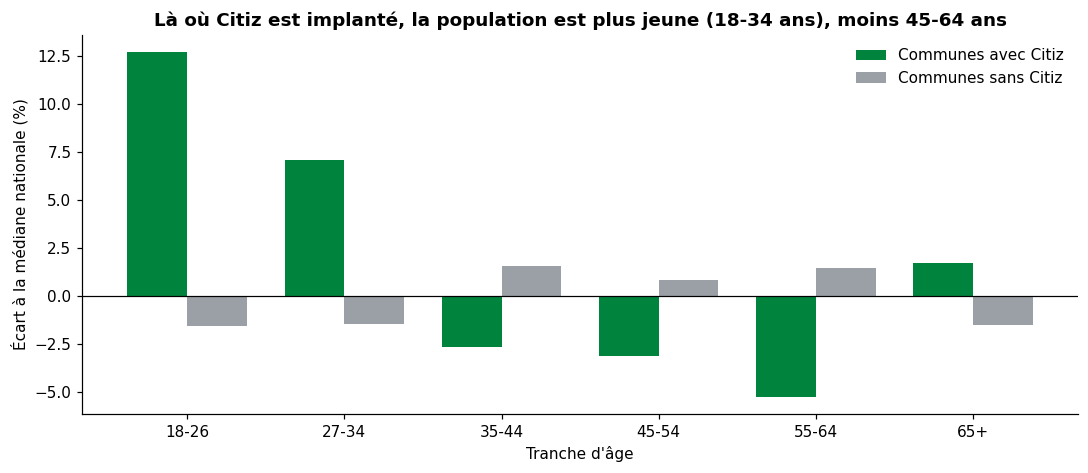

In [17]:
# Part de chaque tranche d'âge : communes avec Citiz / communes sans Citiz (médiane), rapportée à la médiane des 482 communes
med = big[["s_" + b for b in BANDES]].median()
rel = {p: big[big.present == p][["s_" + b for b in BANDES]].median() / med for p in (True, False)}
x = np.arange(len(BANDES)); w = .38
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - w / 2, 100 * (rel[True].values - 1), w, color=GREEN, label="Communes avec Citiz")
ax.bar(x + w / 2, 100 * (rel[False].values - 1), w, color=GREY, label="Communes sans Citiz")
ax.axhline(0, color="black", lw=.8); ax.set_xticks(x, list(BANDES)); ax.set_xlabel("Tranche d'âge")
ax.set_ylabel("Écart à la médiane nationale (%)")
ax.set_title("Là où Citiz est implanté, la population est plus jeune (18-34 ans), moins 45-64 ans")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

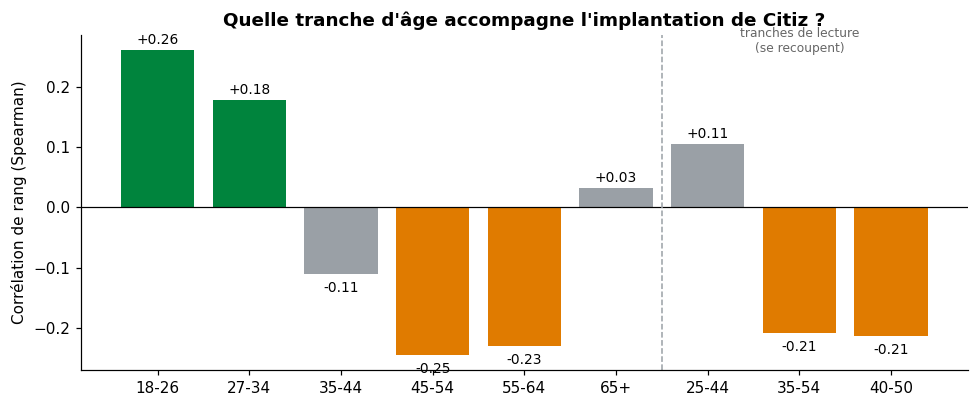

In [18]:
# Corrélation (Spearman) entre la part d'une tranche d'âge et le nombre de véhicules Citiz pour 10 000 habitants
tr = ["18-26", "27-34", "35-44", "45-54", "55-64", "65+", "25-44", "35-54", "40-50"]
rho = pd.Series({t: big["veh10k"].corr(big["s_" + t], method="spearman") for t in tr})
fig, ax = plt.subplots(figsize=(9, 3.8))
cols = [GREEN if v > 0.15 else (ORANGE if v < -0.15 else GREY) for v in rho]
ax.bar(rho.index, rho.values, color=cols)
for i, v in enumerate(rho.values): ax.text(i, v + (.01 if v >= 0 else -.03), f"{v:+.2f}", ha="center", fontsize=9)
ax.axhline(0, color="black", lw=.8); ax.axvline(5.5, color=GREY, ls="--", lw=1)
ax.text(7, ax.get_ylim()[1] * .9, "tranches de lecture\n(se recoupent)", ha="center", fontsize=8, color="#666")
ax.set_ylabel("Corrélation de rang (Spearman)"); ax.set_title("Quelle tranche d'âge accompagne l'implantation de Citiz ?")
plt.tight_layout(); plt.show()

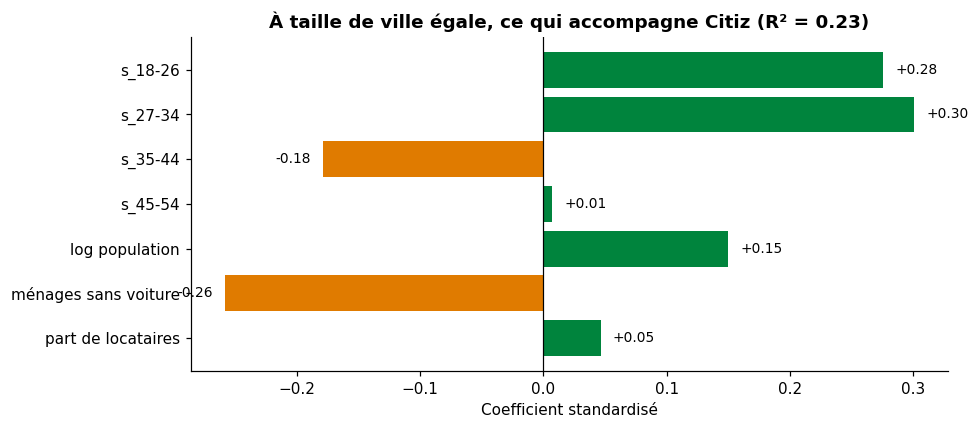

Contrôles : log de la population, part de ménages sans voiture, part de locataires. Les tranches 18-26 et 27-34 ans ressortent positivement ; 35-44 négativement ; 45-54 neutre.


In [19]:
# Régression linéaire standardisée : log(véhicules pour 10 000 hab.) ~ tranches d'âge + taille + sans voiture + locataires
def ols(var_age):
    X = big[var_age].copy()
    X["log population"] = np.log(big["pop"]); X["ménages sans voiture"] = big.sans_voiture; X["part de locataires"] = big.part_locataires
    y = np.log1p(big.veh10k)
    Xs = (X - X.mean()) / X.std(); Xs.insert(0, "const", 1.0)
    beta, *_ = np.linalg.lstsq(Xs.values, ((y - y.mean()) / y.std()).values, rcond=None)
    res = ((y - y.mean()) / y.std()).values - Xs.values @ beta
    r2 = 1 - (res ** 2).sum() / (((y - y.mean()) / y.std()) ** 2).sum()
    return pd.Series(beta[1:], index=Xs.columns[1:]), r2

b1, r1 = ols(["s_18-26", "s_27-34", "s_35-44", "s_45-54"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(b1.index[::-1], b1.values[::-1], color=[GREEN if v > 0 else ORANGE for v in b1.values[::-1]])
for y, v in enumerate(b1.values[::-1]): ax.text(v + (.01 if v >= 0 else -.01), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("Coefficient standardisé")
ax.set_title(f"À taille de ville égale, ce qui accompagne Citiz (R² = {r1:.2f})")
plt.tight_layout(); plt.show()
print("Contrôles : log de la population, part de ménages sans voiture, part de locataires. "
      "Les tranches 18-26 et 27-34 ans ressortent positivement ; 35-44 négativement ; 45-54 neutre.")

### 8.1 Ce que ce test dit, et ne dit pas

- **Il ne confirme pas 25-44 ans.** Citiz est implanté dans des communes plus jeunes (18-34 ans) et pas dans celles qui ont davantage de 45-64 ans. La tranche 25-44 est faiblement associée (corrélation faible) ; 35-54 et 40-50 le sont **négativement**.
- **Il ne contredit pas non plus l'enquête ADEME**, parce qu'il mesure **où sont les stations**, pas **qui les utilise**. Les stations sont dans les grandes villes denses et universitaires, qui sont aussi les plus jeunes ; les abonnés, eux, sont des actifs de 40-50 ans qui y vivent. Les deux faits coexistent.
- **Conséquence pour la stratégie** : le profil des villes où Citiz s'implante est étudiant et dense ; le profil des utilisateurs est actif et plus âgé. Citiz s'installe **là où la mobilité partagée est acceptée** (jeunes, urbains, sans voiture) et vit **de ses abonnés actifs**.

### Que montrent les emplacements des stations ?

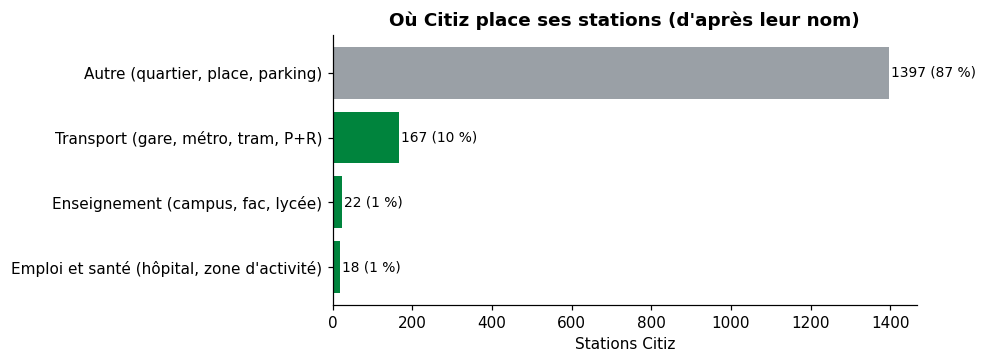

Lecture limitée : le nom n'identifie le lieu que pour une partie des stations ; la catégorie « Autre » est la plus grosse.


In [20]:
def cat(n):
    n = n.lower()
    if re.search(r"gare|sncf|tgv|métro|metro|tram|p\+r|parking relais|station v|bus|aéroport", n): return "Transport (gare, métro, tram, P+R)"
    if re.search(r"univ|fac\b|faculté|campus|iut|crous|lycée|lycee|école|ecole|cité u|étudiant", n): return "Enseignement (campus, fac, lycée)"
    if re.search(r"chu|hôpital|hopital|clinique|zone|zi\b|za\b|parc d|technop|entreprise|siège|business|centre commercial|zac", n): return "Emploi et santé (hôpital, zone d'activité)"
    return "Autre (quartier, place, parking)"

citiz["type_lieu"] = citiz.name.map(cat)
t = citiz.type_lieu.value_counts()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(t.index[::-1], t.values[::-1], color=[GREY if "Autre" in i else GREEN for i in t.index[::-1]])
for y, v in enumerate(t.values[::-1]): ax.text(v + 5, y, f"{v} ({100 * v / t.sum():.0f} %)", va="center", fontsize=9)
ax.set_xlabel("Stations Citiz"); ax.set_title("Où Citiz place ses stations (d'après leur nom)")
plt.tight_layout(); plt.show()
print("Lecture limitée : le nom n'identifie le lieu que pour une partie des stations ; la catégorie « Autre » est la plus grosse.")

Parmi les stations dont le nom permet de reconnaître le lieu, celles proches des **gares et transports** (10 %) sont environ **sept fois plus nombreuses** que celles proches des **campus et lycées** (1 %). C'est un indice, faible, en faveur d'une cible de **voyageurs actifs** plutôt qu'étudiante. **Limite importante** : 87 % des stations ont un nom de quartier ou de rue qui ne dit rien de leur environnement ; ce résultat ne porte que sur 13 % du réseau.

## 9. Le choix de la tranche d'âge change-t-il le classement des villes à conquérir ?

On calcule, pour les 11 grandes villes du Sud, l'effectif de chaque tranche **multiplié par la part de ménages sans voiture de la commune** (proxy de la cible « sans voiture »).

In [21]:
pop = pd.read_csv(RAW / "insee/pop_age_sud_2023.csv", dtype={"geo_code": str})
pop["age_n"] = pop["age"].map(lambda a: 100 if a == "Y_GE100" else (int(a[1:]) if a.startswith("Y") else np.nan))
mv = pd.read_csv(RAW / "insee/menages_voitures_sud_2022.csv", dtype={"CODGEO": str}).set_index("CODGEO")
CODES = {"Marseille": "13055", "Nice": "06088", "Montpellier": "34172", "Toulouse": "31555", "Bordeaux": "33063",
         "Toulon": "83137", "Nîmes": "30189", "Perpignan": "66136", "Aix-en-Provence": "13001", "Avignon": "84007", "Béziers": "34032"}
sv = pd.Series({v: 1 - mv.loc[c, "P22_RP_VOIT1P"] / mv.loc[c, "P22_RP"] for v, c in CODES.items()})
cible_bandes = {"18-26": (18, 26), "25-44": (25, 44), "35-54": (35, 54), "40-50": (40, 50)}
cc = pop[pop.niveau == "commune"]
pool = pd.DataFrame({v: {k: g[g.age_n.between(lo, hi)].population.sum() for k, (lo, hi) in cible_bandes.items()}
                     for v, g in cc.groupby("ville")}).T.mul(sv, axis=0)
veh_ville = {v: citiz[citiz.commune_code == c].n_vehicles.sum() for v, c in CODES.items()}
pool["Citiz (véh.)"] = pd.Series(veh_ville)
sans = pool[pool["Citiz (véh.)"] < 20].drop(columns="Citiz (véh.)")      # villes sans Citiz (ou présence marginale)
rangs = sans.rank(ascending=False).astype(int)
display(sans.round(0).sort_values("40-50", ascending=False))
display(rangs.sort_values("40-50"))

,18-26,25-44,35-54,40-50
Nice,"15,864.0","32,592.0","33,152.0","18,035.0"
Montpellier,"23,102.0","28,868.0","22,063.0","11,856.0"
Toulon,"5,139.0","11,771.0","11,340.0","6,125.0"
Nîmes,"5,454.0","8,951.0","8,978.0","4,884.0"
Aix-en-Provence,"6,896.0","9,188.0","8,066.0","4,390.0"
Perpignan,"3,869.0","7,362.0","7,409.0","4,120.0"
Avignon,"3,046.0","5,923.0","5,651.0","3,102.0"
Béziers,"2,111.0","4,516.0","4,697.0","2,536.0"


,18-26,25-44,35-54,40-50
Nice,2,1,1,1
Montpellier,1,2,2,2
Toulon,5,3,3,3
Nîmes,4,5,4,4
Aix-en-Provence,3,4,5,5
Perpignan,6,6,6,6
Avignon,7,7,7,7
Béziers,8,8,8,8


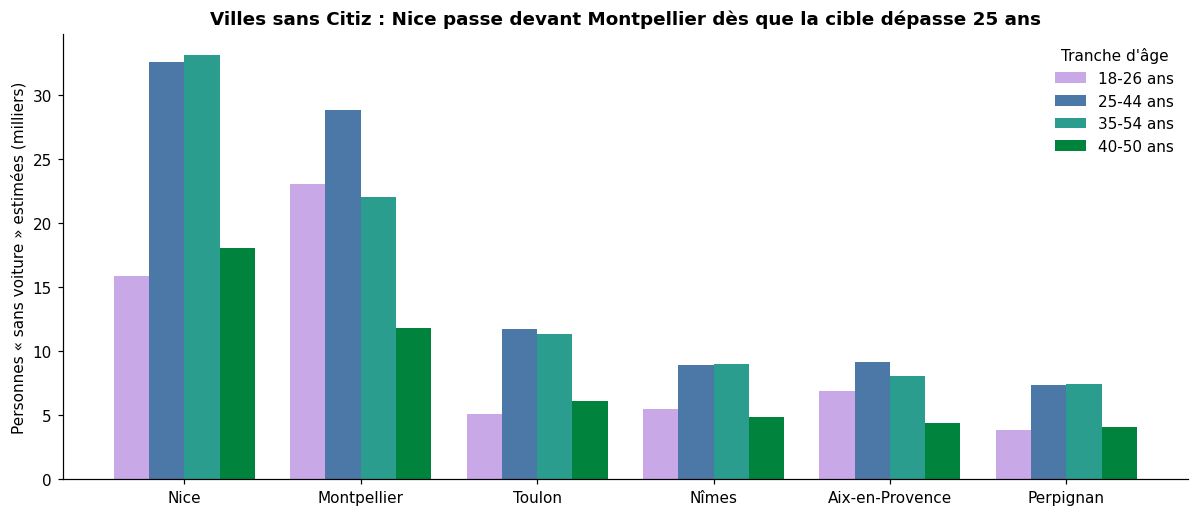

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.8))
villes = sans.sort_values("35-54", ascending=False).index[:6]
x = np.arange(len(villes)); w = .2
for i, (b, col) in enumerate(zip(cible_bandes, ["#C9A8E8", BLUE, "#2A9D8F", GREEN])):
    ax.bar(x + (i - 1.5) * w, sans.loc[villes, b] / 1e3, w, color=col, label=f"{b} ans")
ax.set_xticks(x, villes); ax.set_ylabel("Personnes « sans voiture » estimées (milliers)")
ax.set_title("Villes sans Citiz : Nice passe devant Montpellier dès que la cible dépasse 25 ans")
ax.legend(frameon=False, title="Tranche d'âge"); plt.tight_layout(); plt.show()

### Résultat robuste
- Pour **toute cible adulte (25-44, 35-54 ou 40-50 ans)**, **Nice est 1re et Montpellier 2e**, puis Toulon 3e. Seuls les rangs 4 et 5 (Nîmes, Aix-en-Provence) s'échangent selon la tranche. Choisir 25-44 plutôt que 40-50 ne change pas les deux premières places.
- **Seule la cible 18-26 ans inverse Nice et Montpellier** : Montpellier devient première.
- La vraie question stratégique n'est donc pas « 25-44 ou 40-50 », mais **« étudiants ou actifs ? »**.

## 10. Quel marché pour Citiz dans les villes sans Citiz ? (hypothèse de référence)

On retient la cible **25-54 ans sans voiture** : elle couvre le cœur observé de l'autopartage en boucle (40-50 ans, ADEME 2022) et la tranche plus jeune que Citiz recrute dans les villes universitaires. On applique aux villes sans Citiz **le taux de couverture que Citiz a déjà** à Marseille, Toulouse et Bordeaux. C'est un **ordre de grandeur de marché atteignable**, pas une prévision.

,véh. Citiz pour 10 000 personnes de la cible
Marseille,16.3
Toulouse,24.2
Bordeaux,35.7


,cible 25-54 sans voiture,flotte basse,flotte haute,CA bas (M€/an),CA haut (M€/an)
Nice,"49,120.2",80.0,175.0,0.7,1.5
Montpellier,"39,000.9",64.0,139.0,0.6,1.2
Toulon,"17,412.8",28.0,62.0,0.2,0.5
Nîmes,"13,482.7",22.0,48.0,0.2,0.4
Aix-en-Provence,"13,233.4",22.0,47.0,0.2,0.4
Perpignan,"11,127.3",18.0,40.0,0.2,0.3
Avignon,"8,640.0",14.0,31.0,0.1,0.3
Béziers,"6,959.3",11.0,25.0,0.1,0.2


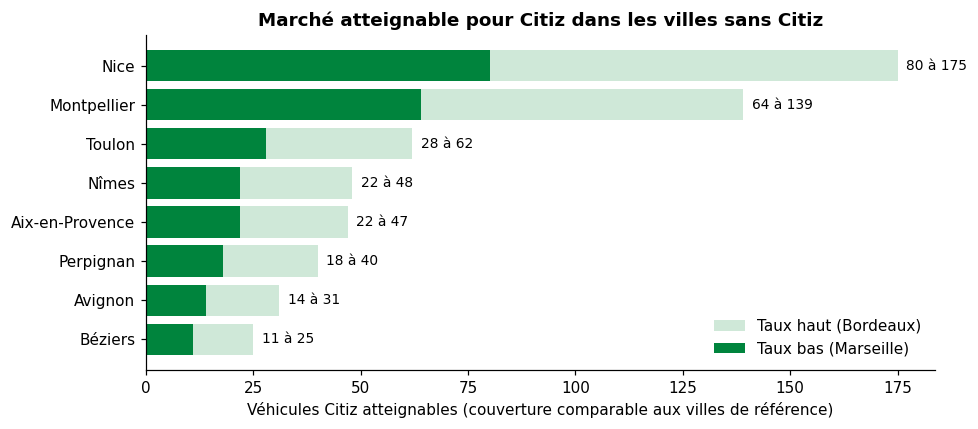

In [23]:
CA_PAR_VEHICULE = 8700   # €/véhicule/an : CA Citiz du 1er semestre 2024 x 2 / 2 560 véhicules (notebook 01, estimation)
c2554 = pd.Series({v: g[g.age_n.between(25, 54)].population.sum() for v, g in cc.groupby("ville")}) * sv
ref = ["Marseille", "Toulouse", "Bordeaux"]
taux = (pool.loc[ref, "Citiz (véh.)"] / c2554[ref] * 10000).rename("véh. Citiz pour 10 000 personnes de la cible")
display(taux.to_frame().round(1))

cibles = list(sans.index)
pot = pd.DataFrame({"cible 25-54 sans voiture": c2554[cibles]})
pot["flotte basse"] = (pot.iloc[:, 0] * taux.min() / 10000).round(0)
pot["flotte haute"] = (pot.iloc[:, 0] * taux.max() / 10000).round(0)
pot["CA bas (M€/an)"] = pot["flotte basse"] * CA_PAR_VEHICULE / 1e6
pot["CA haut (M€/an)"] = pot["flotte haute"] * CA_PAR_VEHICULE / 1e6
pot = pot.sort_values("flotte haute", ascending=False)
display(pot.round(1))

fig, ax = plt.subplots(figsize=(9, 4))
o = pot.iloc[::-1]
ax.barh(o.index, o["flotte haute"], color="#CFE8D8", label=f"Taux haut ({taux.idxmax()})")
ax.barh(o.index, o["flotte basse"], color=GREEN, label=f"Taux bas ({taux.idxmin()})")
for y, (lo, hi) in enumerate(zip(o["flotte basse"], o["flotte haute"])): ax.text(hi + 2, y, f"{lo:.0f} à {hi:.0f}", va="center", fontsize=9)
ax.set_xlabel("Véhicules Citiz atteignables (couverture comparable aux villes de référence)")
ax.set_title("Marché atteignable pour Citiz dans les villes sans Citiz")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Réserves** : (1) à Montpellier, une partie de ce marché est déjà servie par Modulauto (hors GBFS, 110 voitures en Occitanie en 2024) ; (2) à Nice, il n'y a plus d'opérateur en station depuis l'arrêt de Mobilize Share (juin 2026), mais deux opérateurs y ont déjà arrêté ; (3) le CA par véhicule est une moyenne nationale, pas un résultat local.

### 10.1 Pourquoi l'autopartage n'a pas tenu à Nice ?

Nice est notre priorité 1, mais deux services en station s'y sont arrêtés. Avant de recommander Nice, il faut comprendre pourquoi.

**Chronologie** (sources en fin de section)

| Période | Service | Modèle | Taille | Fin |
|---|---|---|---|---|
| 2011-2018 | **Auto Bleue** (délégation de service public, Venap : Veolia-Transdev / EDF) | 100 % électrique, en boucle (« Zen ») **et** aller simple entre stations (« Flex ») ; free-floating « Izzie » ajouté en 2017 | jusqu'à ~210 véhicules, 66-68 stations, 8 100 adhérents (2015) | 31/12/2018, fin de la délégation |
| 2019-2026 | **Renault Mobility** puis **Mobilize Share** (label autopartage de la Métropole) | 100 % électrique, en boucle | 57 Zoé au départ, 62-65 véhicules, 38 stations | 30/06/2026, arrêt décidé par Renault |
| depuis 2021 | **Getaround** (partenariat avec la Métropole) | voitures de particuliers + flotte connectée | 200+ véhicules, occupation 60-76 % | toujours actif |

**Ce que disent les sources**

1. **Un modèle financé par la collectivité, pas par l'usager (Auto Bleue).** Investissement de 2,8 M€ et 1,4 M€ de fonctionnement par an (2012) ; « le business plan n'a pas été construit sur la rentabilité ». En 2018, l'AVEM écrit que le marché n'était pas mûr en 2011 pour fonctionner à grande échelle sans contributions publiques importantes. En 2017, le directeur de Citiz, Jean-Baptiste Schmider, estimait lors d'un débat FNAUT que le système en station de Nice « ne semble pas fonctionner », et que la ville lançait un free-floating financé par la délégation à hauteur d'environ 20 M€ pour une centaine de véhicules.
2. **Un pari technologique coûteux : le 100 % électrique de première génération.** Autonomie de 70 à 130 km, environ 6 h de recharge, environ 40 000 € par station équipée. Chaque voiture immobilisée pour se recharger ne se loue pas.
3. **L'aller simple (« Flex ») pèse sur les coûts.** Locations courtes (45 min en Flex contre 3 h en boucle) ; un service aller simple doit repositionner les voitures, ce qui coûte cher. Dès 2012, la ville notait que les trajets domicile-travail en boucle n'étaient pas rentables pour l'usager.
4. **Mobilize Share : un arrêt décidé au niveau du groupe Renault, pas forcément un échec local.** Le 12 décembre 2025, Renault sort de l'autopartage « faute de synergies avec le reste du groupe ou de perspectives de rentabilité » : fin de Zity (Paris en 2024, puis Milan et Madrid) et de Mobilize Share. Aucun bilan d'usage niçois n'a été publié. Locations longues (7 h en moyenne en 2022), donc peu de locations par voiture et par jour.
5. **Getaround capte une partie de la demande à moindre coût** : pas de flotte à financer, 200+ voitures, occupation élevée.

Nos données ajoutent un élément : **le profil de la population niçoise.**

,% 65 ans et plus,% 25-54 ans,% de locataires,% ménages sans voiture
Nice,23.4,36.7,49.7,37.4
Montpellier,14.9,39.6,66.7,31.7
Grenoble,15.3,40.6,61.2,39.0
Strasbourg,14.8,39.7,70.8,39.4
Lyon,14.9,42.4,64.1,40.8
Bordeaux,15.0,43.0,65.4,37.2
Toulouse,13.0,43.0,65.8,32.8


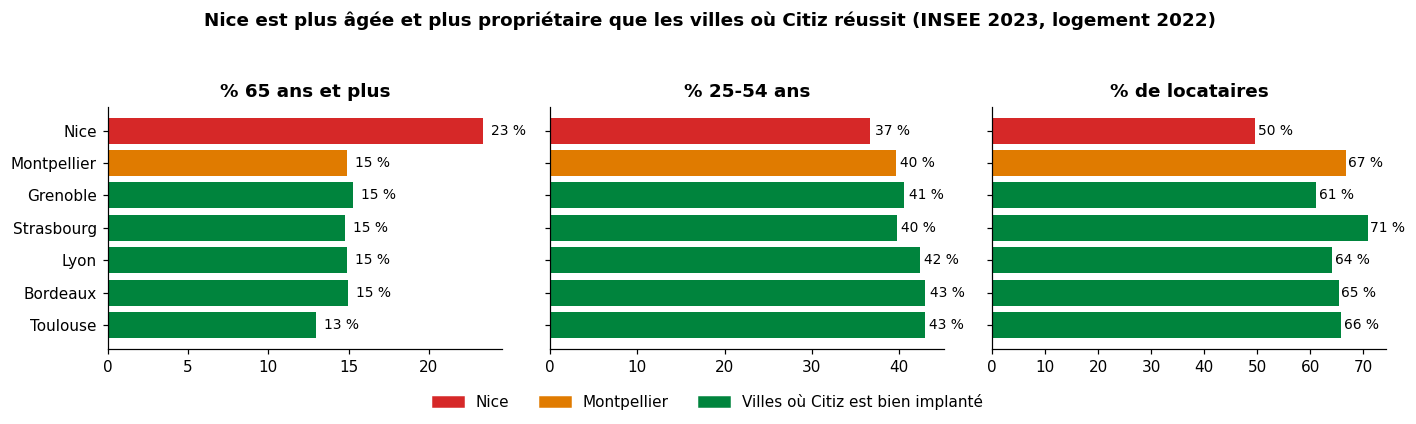

In [24]:
# Profil démographique : Nice comparée aux villes où Citiz réussit
REF_CITIZ = {"Grenoble": "38185", "Strasbourg": "67482", "Lyon": "69123", "Bordeaux": "33063", "Toulouse": "31555"}
comp_villes = {"Nice": "06088", "Montpellier": "34172", **REF_CITIZ}
prof = pd.DataFrame({v: {
    "% 65 ans et plus": 100 * com.loc[com.code == c, "p65_plus"].iloc[0] / com.loc[com.code == c, "pop"].iloc[0],
    "% 25-54 ans": 100 * (com.loc[com.code == c, "p25_44"].iloc[0] + com.loc[com.code == c, "p45_54"].iloc[0]) / com.loc[com.code == c, "pop"].iloc[0],
    "% de locataires": 100 * com.loc[com.code == c, "part_locataires"].iloc[0],
    "% ménages sans voiture": 100 * com.loc[com.code == c, "sans_voiture"].iloc[0],
} for v, c in comp_villes.items()}).T
display(prof.round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
order = ["Nice", "Montpellier"] + list(REF_CITIZ)
for ax, col in zip(axes, ["% 65 ans et plus", "% 25-54 ans", "% de locataires"]):
    vals = prof.loc[order, col]
    ax.barh(order[::-1], vals[::-1], color=["#D62828" if v == "Nice" else (ORANGE if v == "Montpellier" else GREEN) for v in order[::-1]])
    for y, v in enumerate(vals[::-1]): ax.text(v + .5, y, f"{v:.0f} %", va="center", fontsize=9)
    ax.set_title(col)
fig.legend(handles=[Patch(color="#D62828", label="Nice"), Patch(color=ORANGE, label="Montpellier"),
                    Patch(color=GREEN, label="Villes où Citiz est bien implanté")], loc="lower center", ncol=3, frameon=False)
plt.suptitle("Nice est plus âgée et plus propriétaire que les villes où Citiz réussit (INSEE 2023, logement 2022)", fontweight="bold")
plt.tight_layout(rect=(0, 0.07, 1, 0.93)); plt.show()

**Qui sont les ménages sans voiture ?** Nice a la plus forte part de ménages sans voiture du Sud (37 %), mais on peut se demander si ce sont des retraités, qui utilisent peu l'autopartage. La table INSEE PRINC18 (2021) croise le nombre de voitures avec la catégorie socioprofessionnelle de la personne de référence du ménage.

,ménages sans voiture,dont retraités (%),dont actifs (%),ménages ACTIFS sans voiture,% des ménages actifs sans voiture
ville,,,,,
Lyon,"109,060.5",17.1,58.4,"63,676.4",34.3
Marseille,"137,366.3",29.8,44.3,"60,878.0",24.4
Toulouse,"88,879.2",15.3,50.5,"44,927.8",24.3
Nice,"63,322.0",35.8,46.3,"29,288.8",28.4
Bordeaux,"54,858.9",17.4,52.3,"28,706.4",30.2
Strasbourg,"54,279.6",18.2,50.9,"27,650.9",30.4
Montpellier,"49,126.6",17.8,44.9,"22,040.1",22.4
Grenoble,"32,534.6",20.5,48.9,"15,903.1",30.1
Toulon,"23,959.6",39.9,36.2,"8,666.8",16.3


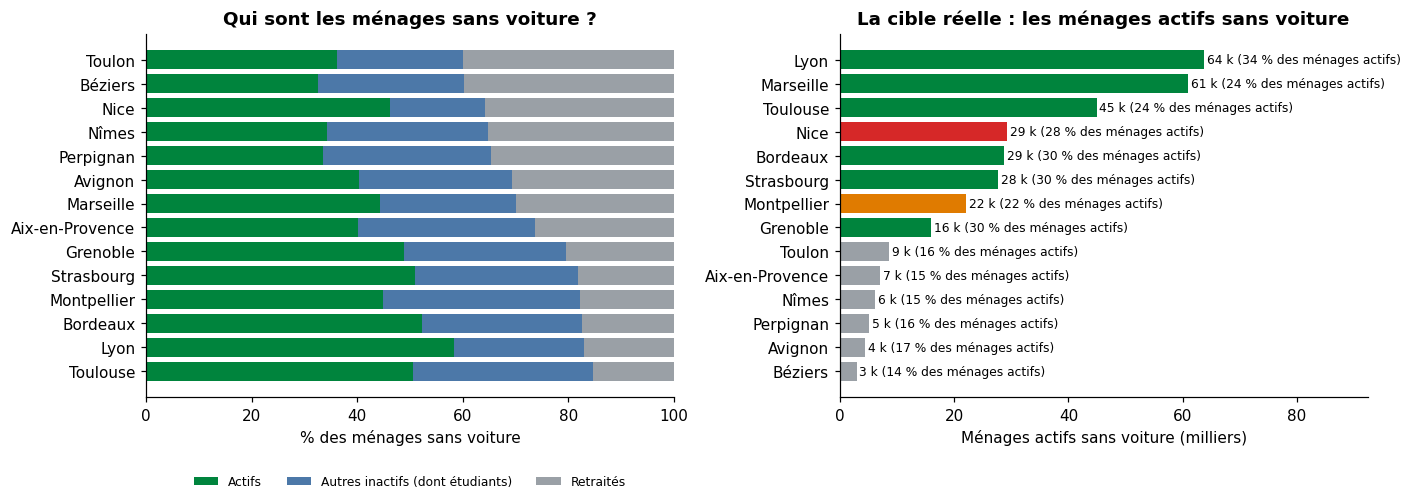

In [25]:
csp = pd.read_csv(RAW / "insee/menages_csp_voiture_2021.csv")
csp["groupe"] = csp.CS1_8.map(lambda c: "Retraités" if c == 7 else ("Autres inactifs (dont étudiants)" if c == 8 else "Actifs"))
sv0 = csp[csp.VOIT == 0].pivot_table(index="ville", columns="groupe", values="NB", aggfunc="sum")
actifs_tot = csp[csp.groupe == "Actifs"].groupby("ville").NB.sum()
sv_tab = pd.DataFrame({
    "ménages sans voiture": sv0.sum(axis=1),
    "dont retraités (%)": 100 * sv0["Retraités"] / sv0.sum(axis=1),
    "dont actifs (%)": 100 * sv0["Actifs"] / sv0.sum(axis=1),
    "ménages ACTIFS sans voiture": sv0["Actifs"],
    "% des ménages actifs sans voiture": 100 * sv0["Actifs"] / actifs_tot,
}).sort_values("ménages ACTIFS sans voiture", ascending=False)
display(sv_tab.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
o = sv_tab.sort_values("dont retraités (%)")
left = np.zeros(len(o))
for g, col in [("Actifs", GREEN), ("Autres inactifs (dont étudiants)", BLUE), ("Retraités", GREY)]:
    share = 100 * sv0.loc[o.index, g] / sv0.loc[o.index].sum(axis=1)
    axes[0].barh(o.index, share, left=left, color=col, label=g); left += share.values
axes[0].set_xlim(0, 100); axes[0].set_xlabel("% des ménages sans voiture")
axes[0].set_title("Qui sont les ménages sans voiture ?"); axes[0].legend(frameon=False, loc="lower center", bbox_to_anchor=(.5, -.28), ncol=3, fontsize=8)
o = sv_tab.sort_values("ménages ACTIFS sans voiture")
axes[1].barh(o.index, o["ménages ACTIFS sans voiture"] / 1e3,
             color=["#D62828" if v == "Nice" else (ORANGE if v == "Montpellier" else (GREEN if v in REF_CITIZ or v == "Marseille" else GREY)) for v in o.index])
for y, (v, p) in enumerate(zip(o["ménages ACTIFS sans voiture"] / 1e3, o["% des ménages actifs sans voiture"])):
    axes[1].text(v + .5, y, f"{v:.0f} k ({p:.0f} % des ménages actifs)", va="center", fontsize=8)
axes[1].set_xlabel("Ménages actifs sans voiture (milliers)"); axes[1].set_title("La cible réelle : les ménages actifs sans voiture")
axes[1].set_xlim(right=o["ménages ACTIFS sans voiture"].max() / 1e3 * 1.45)
plt.tight_layout(); plt.show()

**Lecture**
- **36 % des ménages niçois sans voiture sont des retraités**, contre 15 à 21 % dans les villes où Citiz réussit (Toulouse, Lyon, Bordeaux, Strasbourg). Nice est plus âgée (23 % de 65 ans et plus contre 13 à 15 %) et compte moins de locataires (50 % contre 61 à 71 %). La base « naturelle » de l'autopartage (actifs diplômés, locataires, sans voiture) y est **moins concentrée**.
- **Mais en volume, la cible reste là** : Nice compte **environ 29 000 ménages actifs sans voiture**, autant que Bordeaux et Strasbourg, plus que Montpellier (22 000), et **28 % des ménages actifs niçois n'ont pas de voiture** (contre 22 à 24 % à Montpellier et Toulouse). Avec ce meilleur indicateur, **Nice reste devant Montpellier**.

### Pourquoi ça n'a pas fonctionné : synthèse

| Cause | Niveau de preuve | Ce que Citiz ferait autrement |
|---|---|---|
| Service conçu et payé par la collectivité, sans objectif de rentabilité (Auto Bleue) | **Fort** (déclarations de la ville 2012, AVEM 2018, FNAUT 2017) | Coopérative financée par les usagers ; la collectivité au capital, pas en payeur |
| 100 % électrique de première génération : autonomie faible, recharge longue, bornes coûteuses | **Fort** (caractéristiques publiques de la flotte) | Flotte mixte thermique / hybride / électrique ; électrique là où les bornes existent (les 86 bornes reprises par la Métropole) |
| Aller simple et free-floating : repositionnement coûteux, locations courtes | **Moyen** (durées publiées, analyse FNAUT) | Boucle uniquement, réservation, tarifs longue durée |
| Mobilize : retrait du groupe Renault de toute l'activité d'autopartage | **Fort** pour la décision ; **aucune donnée** sur l'usage à Nice | Ne s'applique pas : l'autopartage est le cœur de métier de Citiz |
| Population plus âgée et plus propriétaire : moins d'utilisateurs naturels par habitant | **Moyen** (nos données INSEE) | Viser les quartiers d'actifs locataires, les gares, les entreprises ; pas toute la ville |
| Getaround capte une partie de la demande avec une offre sans flotte | **Moyen** (occupation 60-76 %) | Se différencier : disponibilité garantie, station fixe, véhicules entretenus |
| Relief, tourisme saisonnier | **Hypothèses non vérifiées** | À documenter avant de conclure |

**Conclusion** : les échecs niçois tiennent surtout à des **modèles économiques** (délégation de service public non rentable, électrique de première génération, aller simple) et à une **décision industrielle de Renault**, plus qu'à une absence de demande. Le modèle de Citiz (coopératif, en boucle, flotte mixte, financé par l'usage) évite la plupart de ces causes. Le risque qui reste est démographique : **cibler précisément les quartiers d'actifs sans voiture**, plutôt que couvrir toute la métropole.

**Sources** : [Auto Bleue, Wikipédia](https://fr.wikipedia.org/wiki/Auto_Bleue) · [Retour d'expérience de Nice, Journal de l'Automobile, 2012](https://journalauto.com/journal-des-flottes/retour-dexperience-dune-collectivite-nice-et-le-succes-dauto-bleue/) · [Auto Bleue, 4 ans, AVEM 2015](https://www.avem.fr/2015/05/12/nice-auto-bleue-celebre-ses-4-ans-dexistence/) · [Renault débarque à Nice, AVEM 2018](https://www.avem.fr/2018/12/17/autopartage-renault-debarque-a-nice/) · [Débat FNAUT, déc. 2017](https://www.fnaut.fr/uploads/2018/05/171207fmjs.pdf) · [Coulisses de Mobilize Share, MotorsActu 2022](https://motorsactu.com/enquete-dans-les-coulisses-de-limplantation-des-services-dautopartage-mobilize-share-et-zity-by-mobilize/) · [Renault : fin de Mobilize Beyond Automotive, L'argus, déc. 2025](https://www.largus.fr/pros/actualite-automobile/groupe-renault-clap-de-fin-pour-mobilize-beyond-automotive-l-autopartage-et-les-quadricycles-30044789.html) · [Les 86 bornes niçoises, Automobile Propre 2026](https://www.automobile-propre.com/articles/nice-bornes-recharge-ex-mobilize-share-reseau-public/) · [Getaround et la Métropole, 2023](https://www.tesla-mag.com/getaround-et-la-metropole-nice-cote-dazur-renforcent-leur-partenariat-pour-lautopartage-electrique/) · INSEE, [table PRINC18 2021](https://www.insee.fr/fr/statistiques/8202355)

## 11. Synthèse : réponse à la problématique

> ### 🎯 Rappel de la problématique
> Comment Citiz peut-il conquérir les grandes villes du Sud où il est absent, en ciblant ses vrais utilisateurs (actifs urbains sans voiture), sans reproduire l'échec des opérateurs qui ont déjà quitté Nice ?

### Ce que montrent les données

**1. Les données sont exploitables, avec des limites connues.** Après nettoyage : 1 604 stations et 2 624 véhicules Citiz, 654 sites concurrents, 9 179 véhicules Getaround uniques (collecte à 48 %). Pas de mesure d'usage, et les opérateurs sans flux ouvert (Modulauto, Zity, Free2Move…) manquent.

**2. Les villes du Sud ne se ressemblent pas.** Montpellier (23,5 % de 18-26 ans) et Toulouse (23,6 %) sont des villes étudiantes ; Nice (11,9 %) et Marseille (12,1 %) ne le sont pas, mais ont le plus de ménages sans voiture (Nice 37,4 %, Marseille 33,2 %).

**3. La cible de Citiz, ce sont des actifs, pas des étudiants.** Les usagers de l'autopartage en boucle ont surtout 40-50 ans, sont actifs à 80 %, diplômés bac +5 à 58 % et sans voiture à 74 % (ADEME 2022). Nos données montrent que Citiz s'implante dans des villes jeunes et denses, ce qui décrit *où* sont les stations, pas *qui* les utilise. Nous retenons la cible **25-54 ans sans voiture**.

**4. Le classement des villes à conquérir est robuste.** Il est confirmé par un indicateur plus direct : Nice compte environ **29 000 ménages actifs sans voiture**, contre 22 000 à Montpellier (INSEE 2021, partie 10.1). Pour toute cible adulte (25-44, 35-54, 40-50 ans), **Nice est 1re et Montpellier 2e** parmi les villes sans Citiz ; Toulon suit, loin derrière. Seule une cible étudiante (18-26 ans) placerait Montpellier devant Nice.

**5. Il reste un marché.** Avec la couverture que Citiz a déjà à Marseille, Toulouse et Bordeaux : **80 à 175 véhicules à Nice** (0,7 à 1,5 M€ de CA par an) et **64 à 139 à Montpellier** (0,6 à 1,2 M€). Toutes les autres villes sans Citiz pèsent moins de 62 véhicules.

### Réponse à la problématique

- **Priorité 1 : Nice.** La plus grande cible adulte sans voiture des villes sans Citiz (environ 49 000 personnes de 25-54 ans), et plus aucun opérateur en station depuis l'arrêt de Mobilize Share en juin 2026. **Pour ne pas répéter les échecs** (Auto Bleue puis Renault/Mobilize, analysés en partie 10.1 : modèles subventionnés, électrique de première génération, retrait industriel de Renault) : démarrer par un **pilote** de quelques stations, mesurer l'usage avant d'étendre, s'appuyer sur des **contrats entreprises et collectivités** (ce qui équilibre Modulauto à Montpellier) et obtenir le **label autopartage** de la Métropole.
- **Priorité 2 : Montpellier.** Cible adulte proche de celle de Nice et la population la plus jeune du Sud, mais un concurrent local solide (Modulauto, adossé à Communauto). Scénario réaliste : **partenariat** ou implantation ciblée (actifs autour des gares, étudiants en complément).
- **Ensuite** : Toulon, Nîmes, Aix-en-Provence, à moindre échelle.

**Limite principale** : l'âge réel des abonnés Citiz et l'usage de ses stations sont inconnus. Ce sont les deux données à demander à Citiz pour confirmer la cible et entraîner le modèle de la tâche 3.

## 12. Faut-il collecter d'autres données ?

Oui. Ce que nous avons suffit pour **le diagnostic** (qui, où, combien, offre visible), pas pour **recommander un emplacement précis** ni chiffrer la rentabilité.

| Priorité | Donnée manquante | Pourquoi | Source |
|---|---|---|---|
| 🔴 1 | **Âge et profil des abonnés Citiz** (par réseau), fréquence, km, durée | La seule donnée qui tranche entre 18-26, 25-44 et 40-50 ans | Citiz (partenaire du hackathon) ; à défaut, rapport complet ADEME/6t 2022 |
| 🔴 1 | **Usage des stations Citiz** (locations par véhicule, taux d'occupation) | Variable à prédire pour le modèle : « une station est un succès si… » | Relevé périodique de `station_status` Citiz |
| 🔴 2 | **Offre hors GBFS** : Modulauto, Zity, Free2Move, Ubeeqo, Marcel | Notre carte sous-estime la concurrence | Sites opérateurs, presse, délibérations des métropoles |
| 🟠 3 | **Revenus par commune ou IRIS** (Filosofi) | L'autopartage vise des ménages à revenus moyens et élevés | [INSEE Filosofi](https://www.insee.fr/fr/statistiques/7233950) |
| 🟠 3 | **Population à l'IRIS ou au carreau de 200 m** | La commune est trop grossière pour placer une station (5 min à pied) | INSEE, carreaux 200 m (cité dans le sujet) |
| 🟠 3 | **Arrêts de transport en commun (GTFS)** | Contrainte Citiz : proximité d'un arrêt ; les stations près des gares sont fréquentes | transport.data.gouv.fr |
| 🟡 4 | **Effectifs étudiants par établissement** | Cible jeune : stations près des campus | Ministère de l'Enseignement supérieur (open data ESR) |
| 🟡 4 | **Emplois et zones d'activité** | Cible active : autopartage pour les entreprises | INSEE (base Flores), SIRENE |
| 🟡 4 | **Réseau piéton OSM** | Zones réelles à 5 minutes à pied | Geofabrik |
| 🟡 5 | **Population saisonnière** (tourisme) | Nice, Perpignan, Montpellier : l'« année » masque les pics | Atout France, INSEE tourisme |